Silhouette Score: 0.2848589191898987


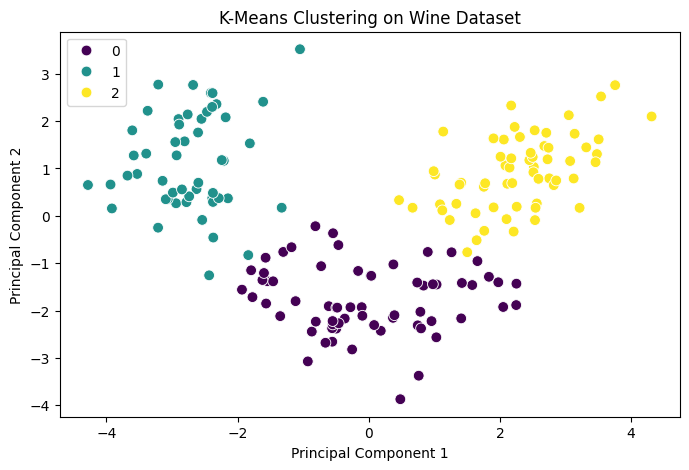


Cluster Distribution:
0    65
1    51
2    62
Name: count, dtype: int64


In [1]:

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# Load Wine dataset
data = load_wine()
X = data.data

# Standardize data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# Silhouette Score
score = silhouette_score(X_scaled, clusters)
print("Silhouette Score:", score)

# Reduce dimensions for visualization
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Visualize clusters
plt.figure(figsize=(8, 5))
sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=clusters,
    palette='viridis',
    s=60
)
plt.title("K-Means Clustering on Wine Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

# Cluster sizes
print("\nCluster Distribution:")
print(__import__('pandas').Series(clusters).value_counts().sort_index())
